In [1]:
# Import packages 
import pandas as pd 
import numpy as np 
import plotly.graph_objects as go
import plotly.express as px
import scipy.stats as stats
from IPython.display import display, HTML

### Basic Data Exploration

In [2]:
# Import data
df = pd.read_csv("house-prices-advanced-regression-techniques/train.csv")

In [3]:
# Create scrollable table within a small window
def create_scrollable_table(df, table_id, title):
    html = f'<h3>{title}</h3>'
    html += f'<div id="{table_id}" style="height:200px; overflow:auto;">'
    html += df.to_html()
    html += '</div>'
    return html

In [4]:
numerical_features = df.select_dtypes(include=[np.number])
numerical_features.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [5]:
# Summary statistics for numerical features by transposing the columns and rows
# Useful to see certain statistics e.g. Standard Deviation etc.
numerical_features = df.select_dtypes(include=[np.number])
summary_stats = numerical_features.describe().T
html_numerical = create_scrollable_table(summary_stats, 'numerical_features', 'Summary statistics for numerical features')

display(HTML(html_numerical))

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [6]:
# Summary statistics for categorical features
# Useful to see certain statistics e.g. Standard Deviation etc.
categorical_features = df.select_dtypes(include=["object", "str"])
cat_summary_stats = categorical_features.describe().T
html_categorical = create_scrollable_table(cat_summary_stats, 'categorical_features', 'Summary statistics for categorical features')

display(HTML(html_categorical ))

,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


In [7]:
# Null values in the dataset
# Potentially to see what is missing, maybe we want to remove the NULL? 
null_values = df.isnull().sum()
html_null_values = create_scrollable_table(null_values.to_frame(), 'null_values', 'Null values in the dataset')

# Percentage of missing values for each feature
missing_percentage = (df.isnull().sum() / len(df)) * 100
html_missing_percentage = create_scrollable_table(missing_percentage.to_frame(), 'missing_percentage', 'Percentage of missing values for each feature')

display(HTML(html_null_values + html_missing_percentage))

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
Street,0
Alley,1369
LotShape,0
LandContour,0
Utilities,0


In [8]:
# To see how big/small dataset is in simple number
df.shape

(1460, 81)

### Exploring the dependent Variable
- Should it be normalised? (adjusted to fit a standard scale)

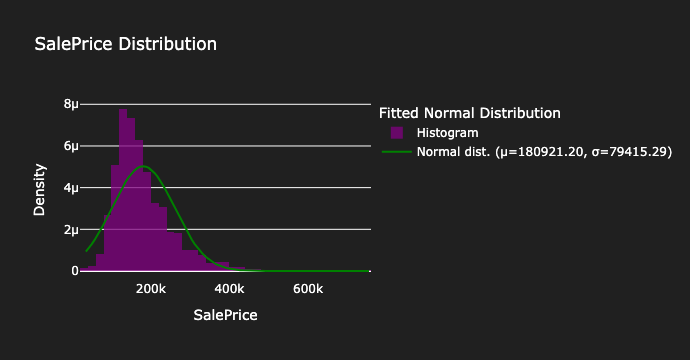

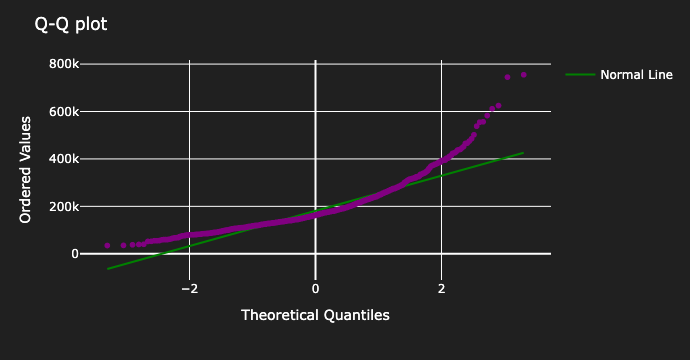

In [9]:
# Fit a normal distribution to the SalePrice data
mu, sigma = stats.norm.fit(df['SalePrice'])

# Create a histogram of the SalePrice column
hist_data = go.Histogram(x=df['SalePrice'], nbinsx=50, name="Histogram", opacity=0.75, histnorm='probability density', marker=dict(color='purple'))

# Calculate the normal distribution based on the fitted parameters
x_norm = np.linspace(df['SalePrice'].min(), df['SalePrice'].max(), 100)
y_norm = stats.norm.pdf(x_norm, mu, sigma)

# Create the normal distribution overlay
norm_data = go.Scatter(x=x_norm, y=y_norm, mode="lines", name=f"Normal dist. (μ={mu:.2f}, σ={sigma:.2f})", line=dict(color="green"))

# Combine the histogram and the overlay
fig = go.Figure(data=[hist_data, norm_data])

# Set the layout for the plot
fig.update_layout(
    title="SalePrice Distribution",
    xaxis_title="SalePrice",
    yaxis_title="Density",
    legend_title_text="Fitted Normal Distribution",
    plot_bgcolor='rgba(32, 32, 32, 1)',
    paper_bgcolor='rgba(32, 32, 32, 1)',
    font=dict(color='white')
)

# Create a Q-Q plot
qq_data = stats.probplot(df['SalePrice'], dist="norm")
qq_fig = px.scatter(x=qq_data[0][0], y=qq_data[0][1], labels={'x': 'Theoretical Quantiles', 'y': 'Ordered Values'}, color_discrete_sequence=["purple"])
qq_fig.update_layout(
    title="Q-Q plot",
    plot_bgcolor='rgba(32, 32, 32, 1)',
    paper_bgcolor='rgba(32, 32, 32, 1)',
    font=dict(color='white')
)

# Calculate the line of best fit
slope, intercept, r_value, p_value, std_err = stats.linregress(qq_data[0][0], qq_data[0][1])
line_x = np.array(qq_data[0][0])
line_y = intercept + slope * line_x

# Add the line of best fit to the Q-Q plot
line_data = go.Scatter(x=line_x, y=line_y, mode="lines", name="Normal Line", line=dict(color="green"))

# Update the Q-Q plot with the normal line
qq_fig.add_trace(line_data)

# Show the plots
fig.show()
qq_fig.show()

## What Questions do we want to ask of the data?
1. Distribution of dwelling types and their relation to sale prices?
2. Does zoning impact sale price?
3. Does street and alley access types effect on sale price?
4. What is the Average sale price by property shape?
5. Is there a Correlation between Property Age and Sale Price
6. Is there a Correlation between Living Area and Sale Price
7. Does price change year to year?

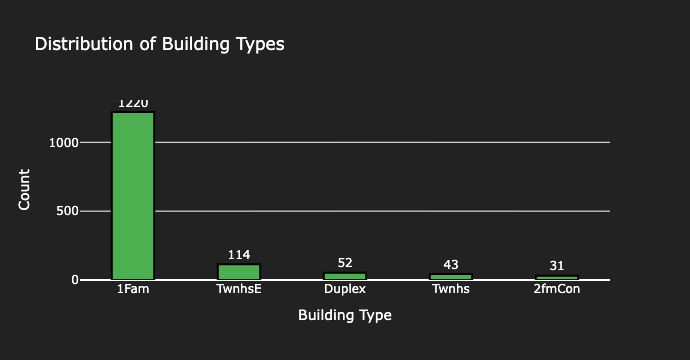

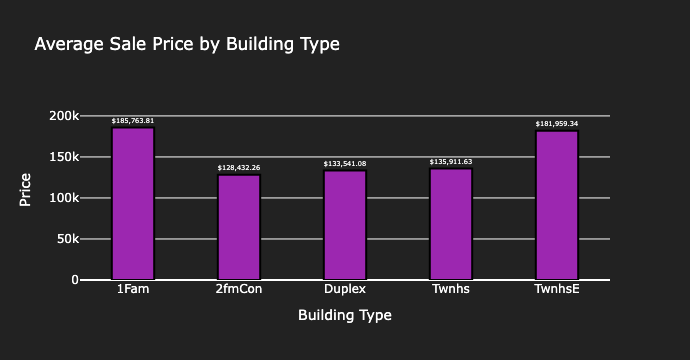

In [10]:
# 1. Distribution of dwelling types and their relation to sale prices
dwelling_types = df['BldgType'].value_counts()
dwelling_prices = df.groupby('BldgType')['SalePrice'].mean()

# Format labels for the second graph
formatted_dwelling_prices = ['$' + f'{value:,.2f}' for value in dwelling_prices.values]

# Create bar charts
fig1 = go.Figure(data=[go.Bar(
    x=dwelling_types.index,
    y=dwelling_types.values,
    marker_color='rgb(76, 175, 80)',
    text=dwelling_types.values,
    textposition='outside',
    width=0.4,
    marker=dict(line=dict(width=2, color='rgba(0,0,0,1)'), opacity=1)
)])
fig1.update_layout(
    title='Distribution of Building Types',
    xaxis_title='Building Type',
    yaxis_title='Count',
    plot_bgcolor='rgba(34, 34, 34, 1)',
    paper_bgcolor='rgba(34, 34, 34, 1)',
    font=dict(color='white')
)

fig2 = go.Figure(data=[go.Bar(
    x=dwelling_prices.index,
    y=dwelling_prices.values,
    marker_color='rgb(156, 39, 176)',
    text=formatted_dwelling_prices,
    textposition='outside',
    width=0.4,
    marker=dict(line=dict(width=2, color='rgba(0,0,0,1)'), opacity=1)
)])
fig2.update_layout(
    title='Average Sale Price by Building Type',
    xaxis_title='Building Type',
    yaxis_title='Price',
    plot_bgcolor='rgba(34, 34, 34, 1)',
    paper_bgcolor='rgba(34, 34, 34, 1)',
    font=dict(color='white')
)

# Show the figures
fig1.show()
fig2.show()


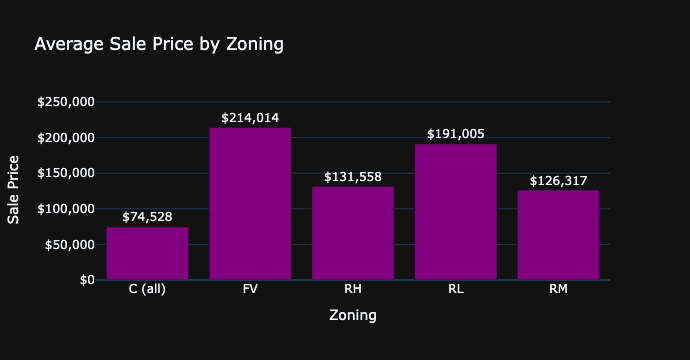

In [11]:
# 2. Zoning impact on sale price
zoning_prices = df.groupby('MSZoning')['SalePrice'].mean()
fig3 = px.bar(x=zoning_prices.index, y=zoning_prices.values, title='Average Sale Price by Zoning',
              color_discrete_sequence=['purple', 'green'], text=zoning_prices.values,
              template='plotly_dark')

fig3.update_traces(texttemplate='$%{text:,.0f}', textposition='outside')
fig3.update_yaxes(title='Sale Price', tickprefix='$', tickformat=',')
fig3.update_xaxes(title='Zoning')
fig3.update_layout(uniformtext_minsize=8, uniformtext_mode='hide')

fig3.show()


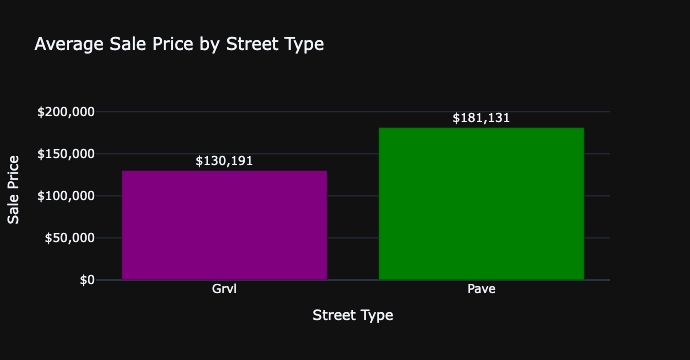

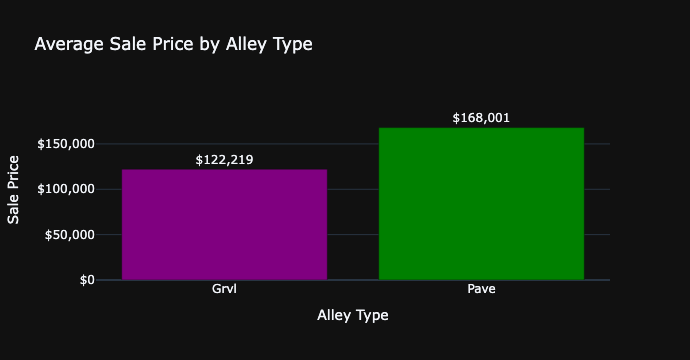

In [12]:
# 3. Street and alley access types effect on sale price
street_prices = df.groupby('Street')['SalePrice'].mean()
alley_prices = df.groupby('Alley')['SalePrice'].mean()

# Street Prices
colors_street = np.where(street_prices.index == 'Pave', 'purple', 'green')
fig5 = px.bar(x=street_prices.index, y=street_prices.values, title='Average Sale Price by Street Type',
              template='plotly_dark', text=street_prices.values,
              color=colors_street, color_discrete_sequence=['purple', 'green'])

fig5.update_traces(texttemplate='$%{text:,.0f}', textposition='outside')
fig5.update_yaxes(title='Sale Price', tickprefix='$', tickformat=',')
fig5.update_xaxes(title='Street Type')
fig5.update_layout(showlegend=False)

# Alley Prices
colors_alley = np.where(alley_prices.index == 'Pave', 'purple', 'green')
fig6 = px.bar(x=alley_prices.index, y=alley_prices.values, title='Average Sale Price by Alley Type',
              template='plotly_dark', text=alley_prices.values,
              color=colors_alley, color_discrete_sequence=['purple', 'green'])

fig6.update_traces(texttemplate='$%{text:,.0f}', textposition='outside')
fig6.update_yaxes(title='Sale Price', tickprefix='$', tickformat=',')
fig6.update_xaxes(title='Alley Type')
fig6.update_layout(showlegend=False)

fig5.show()
fig6.show()


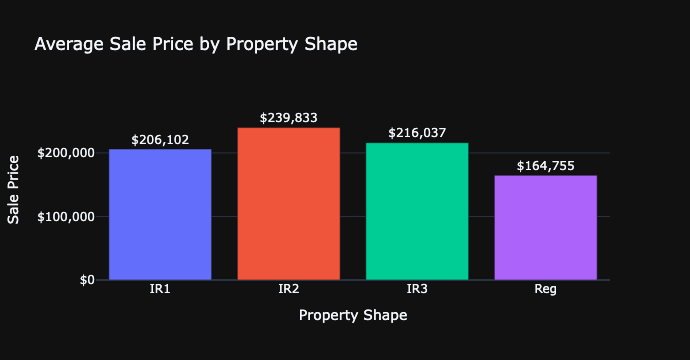

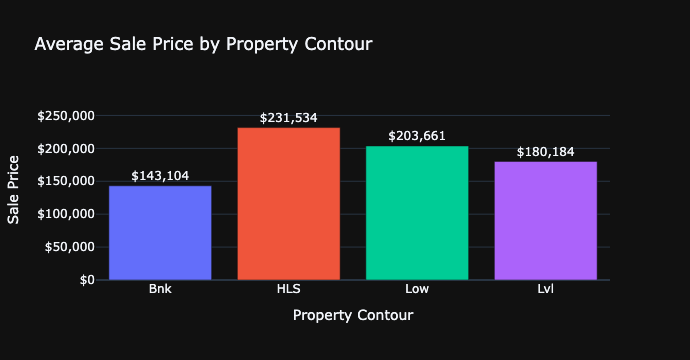

In [13]:
# 4. Average sale price by property shape
colors = px.colors.qualitative.Plotly

shape_prices = df.groupby('LotShape')['SalePrice'].mean()
contour_prices = df.groupby('LandContour')['SalePrice'].mean()
# Shape Prices
fig7 = px.bar(x=shape_prices.index, y=shape_prices.values, title='Average Sale Price by Property Shape',
              template='plotly_dark', text=shape_prices.values)

fig7.update_traces(marker_color=colors, texttemplate='$%{text:,.0f}', textposition='outside')
fig7.update_yaxes(title='Sale Price', tickprefix='$', tickformat=',')
fig7.update_xaxes(title='Property Shape')
fig7.update_layout(showlegend=False)

# Contour Prices
fig8 = px.bar(x=contour_prices.index, y=contour_prices.values, title='Average Sale Price by Property Contour',
              template='plotly_dark', text=contour_prices.values)

fig8.update_traces(marker_color=colors, texttemplate='$%{text:,.0f}', textposition='outside')
fig8.update_yaxes(title='Sale Price', tickprefix='$', tickformat=',')
fig8.update_xaxes(title='Property Contour')
fig8.update_layout(showlegend=False)

fig7.show()
fig8.show()


Correlation between Property Age and Sale Price: -0.5233504175468159


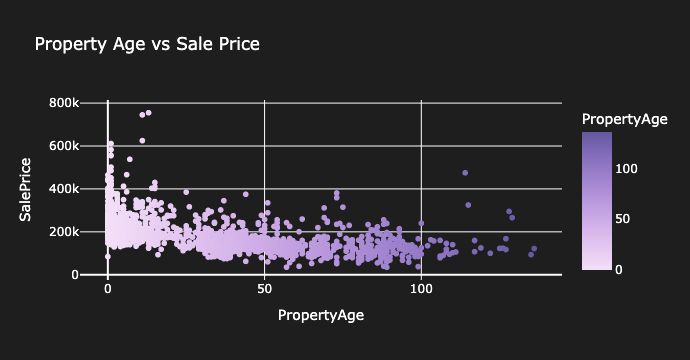

In [14]:
# 5. Calculate Property Age
df['PropertyAge'] = df['YrSold'] - df['YearBuilt']

# Calculate Correlation between Property Age and Sale Price
age_price_corr = df['PropertyAge'].corr(df['SalePrice'])
print(f'Correlation between Property Age and Sale Price: {age_price_corr}')

# Create a scatter plot to visualize the relationship between Property Age and Sale Price
fig9 = px.scatter(df, x='PropertyAge', y='SalePrice', title='Property Age vs Sale Price', color='PropertyAge', color_continuous_scale=px.colors.sequential.Purp)

fig9.update_layout(plot_bgcolor='rgb(30,30,30)', paper_bgcolor='rgb(30,30,30)', font=dict(color='white'))

fig9.show()

Correlation between Living Area (above grade) and Sale Price: 0.7086244776126519


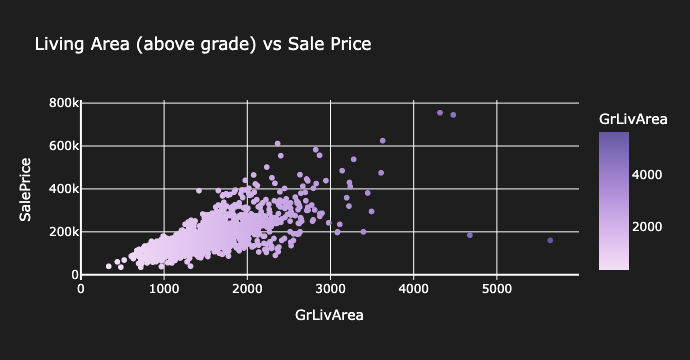

In [15]:
# 6. Calculate Correlation between Living Area and Sale Price
living_area_price_corr = df['GrLivArea'].corr(df['SalePrice'])
print(f'Correlation between Living Area (above grade) and Sale Price: {living_area_price_corr}')

# Create a scatter plot to visualize the relationship between Living Area and Sale Price
fig10 = px.scatter(df, x='GrLivArea', y='SalePrice', title='Living Area (above grade) vs Sale Price', color='GrLivArea', color_continuous_scale=px.colors.sequential.Purp)

fig10.update_layout(plot_bgcolor='rgb(30,30,30)', paper_bgcolor='rgb(30,30,30)', font=dict(color='white'))

fig10.show()

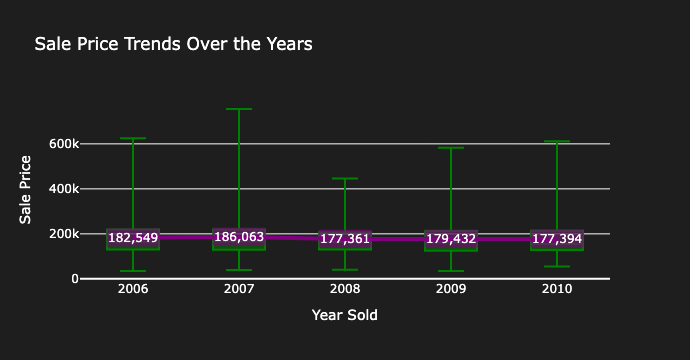

In [16]:
# 7. Box plot of price over the years
yearly_avg_sale_price = df.groupby('YrSold')['SalePrice'].mean()

fig13 = px.box(df, x='YrSold', y='SalePrice', title='Sale Price Trends Over the Years',
               points=False, color_discrete_sequence=['green'])

fig13.add_trace(px.line(x=yearly_avg_sale_price.index, y=yearly_avg_sale_price.values).data[0])

fig13.update_traces(line=dict(color='purple', width=4), selector=dict(type='scatter', mode='lines'))

for year, avg_price in yearly_avg_sale_price.items():
    fig13.add_annotation(
        x=year,
        y=avg_price,
        text=f"{avg_price:,.0f}",
        font=dict(color='white'),
        showarrow=False,
        bgcolor='rgba(128, 0, 128, 0.6)'
    )

fig13.update_layout(
    plot_bgcolor='rgb(30,30,30)',
    paper_bgcolor='rgb(30,30,30)',
    font=dict(color='white'),
    xaxis_title='Year Sold',
    yaxis_title='Sale Price'
)

fig13.show()

## Creating a Data Pipeline
Automated system that moves data from one or more source to destination, often reshaping along the way. Pipelines let you chain actions, (e.g. data cleaning pipeline -> ml learning pipeline -> output)
Goal - clean up data and make it useable in a model. (potentially normalise data, impute data, scale data, onehot encode data). 

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


# Define transformers for numerical and categorical columns
# Imputer fills missing values by filling in with mean 
# Scalar standardizes numbers into one scale
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Onehot converts text to numbers
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output = False))
])

In [18]:
# Update categorical and numerical columns, sepereates columns by data type
categorical_columns = df.select_dtypes(include=['object', 'str', 'category']).columns
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

# Remove target variable from numerical columns
#In machine learning, we divide our data into features (X): information used to make predicitions and Target (y) : the value we try to predict. When trying to predict the target variable, we don't include the answer to the model so it learns it, if it knows this is called target leakage.
numerical_columns = numerical_columns.drop('SalePrice')

# Combine transformers using ColumnTransformer
# Tells python which pipeline to apply to which columns, e.g. categorical columns to fill missing values and onehot encode, numerical columns fill missing values and standardize values.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ],remainder = 'passthrough')

# Create a pipeline with the preprocessor
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor)])

# Apply the pipeline to your dataset
# Seperate features and target and apply the preprocessing pipeline.
X = df.drop('SalePrice', axis=1)
y = np.log(df['SalePrice']) #normalize dependent variable by log of it
X_preprocessed = pipeline.fit_transform(X)

In [19]:
# Import machine learning models 
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score

# Split the data into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_preprocessed, y, test_size=0.2, random_state=42)

# Define the models
models = {
    'LinearRegression': LinearRegression(),
    'RandomForest': RandomForestRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42)
}

# Define the hyperparameter grids for each model
# I.E. Setting you choose before training a model, e.g. how many trees to create, how complicated each tree becomes, and how many data points are needed before a tree can make a split. 
param_grids = {
    'LinearRegression': {},
    'RandomForest': {
        'n_estimators': [100, 200, 500],
        'max_depth': [None, 10, 30],
        'min_samples_split': [2, 5, 10],
    },
    'XGBoost': {
        'n_estimators': [100, 200, 500],
        'learning_rate': [0.01, 0.1, 0.3],
        'max_depth': [3, 6, 10],
    }
}

# 3-fold cross-validation
# We test the model 3 times using different portions of the training data e.g. 1st round first 33% is tested and 66% is trained, 2nd round first 33% train, then 33% tested, then 33% trained, 3rd round, first 66% train, last 33% tested. .
cv = KFold(n_splits=3, shuffle=True, random_state=42)

# Train and tune the models
# The main training loop
grids = {}
for model_name, model in models.items():
    #print(f'Training and tuning {model_name}...')
    grids[model_name] = GridSearchCV(estimator=model, param_grid=param_grids[model_name], cv=cv, scoring='neg_mean_squared_error', n_jobs=-1, verbose=2)
    grids[model_name].fit(X_train, y_train)
    # Find the best settings and score, lower RMSE = Better predictions
    best_params = grids[model_name].best_params_
    best_score = np.sqrt(-1 * grids[model_name].best_score_)
    
    print(f'Best parameters for {model_name}: {best_params}')
    print(f'Best RMSE for {model_name}: {best_score}\n')

Fitting 3 folds for each of 1 candidates, totalling 3 fits
Best parameters for LinearRegression: {}
Best RMSE for LinearRegression: 0.17616568200328325

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Best parameters for RandomForest: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 500}
Best RMSE for RandomForest: 0.1529576759711819

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Best parameters for XGBoost: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Best RMSE for XGBoost: 0.13739245259181646



In [20]:
# Learns patterns from data using interconnected artificial neurons
from sklearn.neural_network import MLPRegressor

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Create an MLPRegressor instance
# Creating neural network, i.e. student practicing predictions and adjusting approach adter mistakes
mlp = MLPRegressor(random_state=42,max_iter=10000, n_iter_no_change = 3,learning_rate_init=0.001)

# Define the parameter grid for tuning
# Tests different neural network structures, more layers don't automaticaly mean better predictions, a more complex network may be overfit or harder to train.
param_grid = {
    'hidden_layer_sizes': [(10,), (10,10), (10,10,10), (25)],
    'activation': ['relu', 'tanh'],
    'solver': ['adam'],
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate': ['constant', 'invscaling', 'adaptive'],
}

# Create the GridSearchCV object
# Finds best settings 
grid_search_mlp = GridSearchCV(mlp, param_grid, scoring='neg_mean_squared_error', cv=3, n_jobs=-1, verbose=1)

# Fit the model on the training data
grid_search_mlp.fit(X_train_scaled, y_train)

# Print the best parameters found during the search
print("Best parameters found: ", grid_search_mlp.best_params_)

# Evaluate the model on the test data
best_score = np.sqrt(-1 * grid_search_mlp.best_score_)
print("Best CV RMSE: ", best_score)

Fitting 3 folds for each of 72 candidates, totalling 216 fits
Best parameters found:  {'activation': 'relu', 'alpha': 0.001, 'hidden_layer_sizes': (10, 10), 'learning_rate': 'constant', 'solver': 'adam'}
Best CV RMSE:  0.22778267781613565


### PCA (Principal Component Analysis)
Method to reduce number of features your model has to work with.
Originally our housing data set had 81 columns, after OneHotEncoding categorical features, the number of columns increases because each category becomes its own numerical column. 
Some of features may contain overlapping information, e.g. GarageCars, GarageArea, which information may be correlated.
PCA creates new features called prinicpal components by combining information from original features.
The goal is to keep much of the variation in your data using fewer features.
e.g. if you had 250 processed columns, PCA might find that 100 components retain 95% of their variance
e.g. if PC1 has 60% explained variance, it means PC1 captures 60% of the differences between the houses in dataset. e.g. "PC1 captures 60% of the differences in the characteristics of the houses, and those differences might be largely related to house size."

In [21]:
#PCA
from sklearn.decomposition import PCA

#Creating PCA object and analyse preprocessed data 
pca = PCA()
X_pca_pre = pca.fit_transform(X_preprocessed)

# Calculate the cumulative explained variance
cumulative_explained_variance = np.cumsum(pca.explained_variance_ratio_)

# Keep enough components to retain 95% variance
n_components = np.argmax(cumulative_explained_variance >= 0.95) + 1

# Create a new pipeline
pca = PCA(n_components=n_components)
pipeline_pca = Pipeline(steps=
                        [('preprocessor', preprocessor),
                        ('pca', pca)])

# Apply the pipeline
X_pca = pipeline_pca.fit_transform(X)

In [22]:
# Running same models with new PCA reduced data 
# Goal is to predict house prices just as accurately or even better using fewer features
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score

# Split the data into training and testing sets
from sklearn.model_selection import train_test_split
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(X_pca, y, test_size=0.2, random_state=42)

# Define the models
models = {
    'LinearRegression': LinearRegression(),
    'RandomForest': RandomForestRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42)
}

# Define the hyperparameter grids for each model
param_grids = {
    'LinearRegression': {},
    'RandomForest': {
        'n_estimators': [100, 200, 500],
        'max_depth': [None, 10, 30],
        'min_samples_split': [2, 5, 10],
    },
    'XGBoost': {
        'n_estimators': [100, 200, 500],
        'learning_rate': [0.01, 0.1, 0.3],
        'max_depth': [3, 6, 10],
    }
}

# 3-fold cross-validation
cv = KFold(n_splits=3, shuffle=True, random_state=42)

# Train and tune the models
grids_pca = {}
for model_name, model in models.items():
    #print(f'Training and tuning {model_name}...')
    grids_pca[model_name] = GridSearchCV(estimator=model, param_grid=param_grids[model_name], cv=cv, scoring='neg_mean_squared_error', n_jobs=-1, verbose=2)
    grids_pca[model_name].fit(X_train_pca, y_train_pca)
    best_params = grids_pca[model_name].best_params_
    best_score = np.sqrt(-1 * grids_pca[model_name].best_score_)
    
    print(f'Best parameters for {model_name}: {best_params}')
    print(f'Best RMSE for {model_name}: {best_score}\n')

Fitting 3 folds for each of 1 candidates, totalling 3 fits
Best parameters for LinearRegression: {}
Best RMSE for LinearRegression: 0.16384707690258835

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Best parameters for RandomForest: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 500}
Best RMSE for RandomForest: 0.15196375809489424

Fitting 3 folds for each of 27 candidates, totalling 81 fits
[CV] END max_depth=None, min_samples_split=2, n_estimators=100; total time=   0.9s
[CV] END max_depth=None, min_samples_split=10, n_estimators=100; total time=   0.6s
[CV] END max_depth=None, min_samples_split=10, n_estimators=100; total time=   0.6s
[CV] END max_depth=None, min_samples_split=10, n_estimators=200; total time=   1.2s
[CV] END max_depth=10, min_samples_split=2, n_estimators=200; total time=   1.4s
[CV] END max_depth=10, min_samples_split=5, n_estimators=200; total time=   1.2s
[CV] END max_depth=10, min_samples_split=10, n_estimators=500; total time=   2.8

/Users/prakashpadala/Library/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV] END max_depth=None, min_samples_split=2, n_estimators=200; total time=   1.7s
[CV] END max_depth=None, min_samples_split=10, n_estimators=100; total time=   0.6s
[CV] END max_depth=None, min_samples_split=10, n_estimators=500; total time=   2.9s
[CV] END max_depth=10, min_samples_split=10, n_estimators=100; total time=   0.5s
[CV] END max_depth=10, min_samples_split=10, n_estimators=500; total time=   2.8s
[CV] END max_depth=30, min_samples_split=5, n_estimators=200; total time=   1.3s
[CV] END max_depth=30, min_samples_split=10, n_estimators=500; total time=   2.6s
[CV] END ..learning_rate=0.01, max_depth=6, n_estimators=200; total time=   0.5s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=100; total time=   0.1s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=100; total time=   0.1s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=200; total time=   0.1s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=200; total time=   0.1s
[CV] END ...learn

| Model | Without PCA | With PCA | Change | 
| ----- | ----------- | -------- | ------ |
Linear regression | 0.1762 | 0.1635 | Improveed 7.2% |
Random Forest | 0.1530 | 0.1518 | Improved 0.7% | 
XGBoost | 0.1374 | 0.1380 | Worsened 0.5% | 

In [23]:
# Testing a neural neutwork (MLPRegressor) using PCA-reduced housing data
# Goal - does reducing the number of features using PCA help the neural network predict house prices more accurately?
from sklearn.neural_network import MLPRegressor

X_train_scaled_pca = X_train_pca.copy()
X_test_scaled_pca = X_test_pca.copy()

# Create an MLPRegressor instance
mlp = MLPRegressor(random_state=42,max_iter=10000, n_iter_no_change = 3,learning_rate_init=0.001)

# Define the parameter grid for tuning
param_grid = {
    'hidden_layer_sizes': [(10,), (10,10), (10,10,10), (25)],
    'activation': ['relu', 'tanh'],
    'solver': ['adam'],
    'alpha': [0.0001, 0.001, 0.01, .1, 1],
}

# Create the GridSearchCV object
grid_search_mlp_pca = GridSearchCV(mlp, param_grid, scoring='neg_mean_squared_error', cv=3, n_jobs=-1, verbose=1)

# Fit the model on the training data
grid_search_mlp_pca.fit(X_train_scaled_pca, y_train_pca)

# Print the best parameters found during the search
print("Best parameters found: ", grid_search_mlp_pca.best_params_)

# Evaluate the model on the test data
best_score = np.sqrt(-1 * grid_search_mlp_pca.best_score_)
print("Best CV RMSE: ", best_score)

Fitting 3 folds for each of 40 candidates, totalling 120 fits
[CV] END .................................................... total time=   0.0s
[CV] END max_depth=None, min_samples_split=2, n_estimators=500; total time=   4.3s
[CV] END max_depth=10, min_samples_split=2, n_estimators=200; total time=   1.4s
[CV] END max_depth=10, min_samples_split=5, n_estimators=200; total time=   1.2s
[CV] END max_depth=10, min_samples_split=10, n_estimators=200; total time=   1.1s
[CV] END max_depth=30, min_samples_split=2, n_estimators=100; total time=   0.8s
[CV] END max_depth=30, min_samples_split=2, n_estimators=500; total time=   3.9s
[CV] END ..learning_rate=0.01, max_depth=6, n_estimators=200; total time=   0.4s
[CV] END .learning_rate=0.01, max_depth=10, n_estimators=500; total time=   3.4s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=100; total time=   0.0s
[CV] END max_depth=None, min_samples_split=2, n_estimators=200; total time=   2.5s
[CV] END max_depth=None, min_samples_split

| Model | Without PCA | With PCA | Change | 
| ----- | ----------- | -------- | ------ |
Linear regression | 0.1762 | 0.1635 | Improveed 7.2% |
Random Forest | 0.1530 | 0.1518 | Improved 0.7% | 
XGBoost | 0.1374 | 0.1380 | Worsened 0.5% | 
Neural Network (MLP) | 0.2278 | 0.2226 | Improved 2.3% |

Now we are testing how well the trained models predict house prices they've never been trained on. We are checking to see whether those models can make accurate predictions on the 20% test data set.

In [24]:
# Testing models without PCA
from sklearn.metrics import mean_squared_error
for i in grids.keys():
    print (i + ': ' + str(np.sqrt(mean_squared_error(grids[i].predict(X_test), y_test))))

LinearRegression: 0.13212453580847525
RandomForest: 0.14716418956017047
XGBoost: 0.13166735859142514


In [25]:
# Testing models with PCA
from sklearn.metrics import mean_squared_error
for i in grids.keys():
    print (i + ': ' + str(np.sqrt(mean_squared_error(grids_pca[i].predict(X_test_pca), y_test))))

LinearRegression: 0.143056396656701
RandomForest: 0.1528968304242067
XGBoost: 0.14155786355551156


In [26]:
# Testing neural network Without PCA
print( str(np.sqrt(mean_squared_error(grid_search_mlp.predict(X_test_scaled),y_test))))

0.16683910272240587


In [27]:
# Testing neural network with PCA
print( str(np.sqrt(mean_squared_error(grid_search_mlp_pca.predict(X_test_scaled_pca),y_test))))

0.18212397448545933


## Test results

| Model | Without PCA | With PCA | Better Result | 
| ----- | ----------- | -------- | ------ |
Linear regression | 0.1321 | 0.1414 | Without PCA |
Random Forest | 0.1472 | 0.1532 | Without PCA | 
XGBoost | 0.1317 | 0.1420 | Without PCA | 
Neural Network (MLP) | 0.1668 | 0.1822 | Without PCA |

In [28]:
# Reasons we explore these features, some have lots of missing values, some features may describe same general characteristic and can be combined.
var_explore = df[['Fence','Alley','MiscFeature','PoolQC','FireplaceQu','GarageCond','GarageQual','GarageFinish','GarageType','BsmtExposure','BsmtFinType2','BsmtFinType1','BsmtCond','BsmtQual','MasVnrType','Electrical','MSZoning','Utilities','Exterior1st','Exterior2nd','KitchenQual','Functional','SaleType','LotFrontage','GarageYrBlt','MasVnrArea','BsmtFullBath','BsmtHalfBath','GarageCars','GarageArea','TotalBsmtSF']]

display(HTML(create_scrollable_table(var_explore, 'var_explore', 'List of Variables to Explore for Feature Engineering')))

,Fence,Alley,MiscFeature,PoolQC,FireplaceQu,GarageCond,GarageQual,GarageFinish,GarageType,BsmtExposure,BsmtFinType2,BsmtFinType1,BsmtCond,BsmtQual,MasVnrType,Electrical,MSZoning,Utilities,Exterior1st,Exterior2nd,KitchenQual,Functional,SaleType,LotFrontage,GarageYrBlt,MasVnrArea,BsmtFullBath,BsmtHalfBath,GarageCars,GarageArea,TotalBsmtSF
0,NaN,NaN,NaN,NaN,NaN,TA,TA,RFn,Attchd,No,Unf,GLQ,TA,Gd,BrkFace,SBrkr,RL,AllPub,VinylSd,VinylSd,Gd,Typ,WD,65.0,2003.0,196.0,1,0,2,548,856
1,NaN,NaN,NaN,NaN,TA,TA,TA,RFn,Attchd,Gd,Unf,ALQ,TA,Gd,NaN,SBrkr,RL,AllPub,MetalSd,MetalSd,TA,Typ,WD,80.0,1976.0,0.0,0,1,2,460,1262
2,NaN,NaN,NaN,NaN,TA,TA,TA,RFn,Attchd,Mn,Unf,GLQ,TA,Gd,BrkFace,SBrkr,RL,AllPub,VinylSd,VinylSd,Gd,Typ,WD,68.0,2001.0,162.0,1,0,2,608,920
3,NaN,NaN,NaN,NaN,Gd,TA,TA,Unf,Detchd,No,Unf,ALQ,Gd,TA,NaN,SBrkr,RL,AllPub,Wd Sdng,Wd Shng,Gd,Typ,WD,60.0,1998.0,0.0,1,0,3,642,756
4,NaN,NaN,NaN,NaN,TA,TA,TA,RFn,Attchd,Av,Unf,GLQ,TA,Gd,BrkFace,SBrkr,RL,AllPub,VinylSd,VinylSd,Gd,Typ,WD,84.0,2000.0,350.0,1,0,3,836,1145
5,MnPrv,NaN,Shed,NaN,NaN,TA,TA,Unf,Attchd,No,Unf,GLQ,TA,Gd,NaN,SBrkr,RL,AllPub,VinylSd,VinylSd,TA,Typ,WD,85.0,1993.0,0.0,1,0,2,480,796
6,NaN,NaN,NaN,NaN,Gd,TA,TA,RFn,Attchd,Av,Unf,GLQ,TA,Ex,Stone,SBrkr,RL,AllPub,VinylSd,VinylSd,Gd,Typ,WD,75.0,2004.0,186.0,1,0,2,636,1686
7,NaN,NaN,Shed,NaN,TA,TA,TA,RFn,Attchd,Mn,BLQ,ALQ,TA,Gd,Stone,SBrkr,RL,AllPub,HdBoard,HdBoard,TA,Typ,WD,NaN,1973.0,240.0,1,0,2,484,1107
8,NaN,NaN,NaN,NaN,TA,TA,Fa,Unf,Detchd,No,Unf,Unf,TA,TA,NaN,FuseF,RM,AllPub,BrkFace,Wd Shng,TA,Min1,WD,51.0,1931.0,0.0,0,0,2,468,952
9,NaN,NaN,NaN,NaN,TA,TA,Gd,RFn,Attchd,No,Unf,GLQ,TA,TA,NaN,SBrkr,RL,AllPub,MetalSd,MetalSd,TA,Typ,WD,50.0,1939.0,0.0,1,0,1,205,991


In [29]:
#Creating new features that may help model predict house prices more accurately by adding 10 new columns
from sklearn.preprocessing import FunctionTransformer

# feature engineering functions 
def custom_features(df):
    df_out = df.copy()
    df_out['PropertyAge'] = df_out['YrSold'] - df_out['YearBuilt']
    df_out['TotalSF'] = df_out['TotalBsmtSF'] + df_out['1stFlrSF'] + df_out['2ndFlrSF']
    df_out['TotalBath'] = df_out['FullBath'] + 0.5 * df_out['HalfBath'] + df_out['BsmtFullBath'] + 0.5 * df_out['BsmtHalfBath']
    df_out['HasRemodeled'] = (df_out['YearRemodAdd'] != df_out['YearBuilt']).astype(object)
    df_out['Has2ndFloor'] = (df_out['2ndFlrSF'] > 0).astype(object)
    df_out['HasGarage'] = (df_out['GarageArea'] > 0).astype(object)
    df_out['YrSold_cat'] = df_out['YrSold'].astype(object)
    df_out['MoSold_cat'] = df_out['MoSold'].astype(object)
    df_out['YearBuilt_cat'] = df_out['YearBuilt'].astype(object)
    df_out['MSSubClass_cat'] = df_out['MSSubClass'].astype(object)
    
    return df_out

feature_engineering_transformer = FunctionTransformer(custom_features)


In [30]:
# Feature engineering, preprocessing and PCA
# Identify categorical and numerical columns new features
new_cols_categorical = pd.Index(['HasRemodeled', 'Has2ndFloor', 'HasGarage','YrSold_cat', 'MoSold_cat', 'YearBuilt_cat', 'MSSubClass_cat'])
new_cols_numeric = pd.Index(['PropertyAge', 'TotalSF', 'TotalBath'])

# Update categorical and numerical columns
# Combines original columns with newly engineered columns
categorical_columns = df.select_dtypes(include=['object', 'str', 'category']).columns.append(new_cols_categorical).unique()
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.append(new_cols_numeric).unique()

# Remove target variable from numerical columns
numerical_columns = numerical_columns.drop('SalePrice')

# Combine transformers using ColumnTransformer
# Tells python, send numerial features through the numerical transformer, send categorical features through the categorical transformer, keep any other columns unchanged
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ],remainder = 'passthrough')

# Create a pipeline with the preprocessor
pipeline_fe = Pipeline(steps=[
    ('fe', feature_engineering_transformer),
    ('preprocessor', preprocessor),
    ('pca', pca)])

# Apply the pipeline to your dataset
X = df.drop('SalePrice', axis=1)
y = np.log(df['SalePrice'])
X_preprocessed_fe = pipeline_fe.fit_transform(X)

In [31]:
# Split the data into training and testing sets
# Dividing dataset into 80% training (used to teach model patterns in house prices) , 20% testing (used later to evaluate how well the model predicts house prices it hasn't seen during training
from sklearn.model_selection import train_test_split
X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(X_preprocessed_fe, y, test_size=0.2, random_state=42)

# Define the models
models = {
    'LinearRegression': LinearRegression(),
    'RandomForest': RandomForestRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42)
}

# Define the hyperparameter grids for each model
param_grids = {
    'LinearRegression': {},
    'RandomForest': {
        'n_estimators': [100, 200, 500],
        'max_depth': [None, 10, 30],
        'min_samples_split': [2, 5, 10],
    },
    'XGBoost': {
        'n_estimators': [100, 200, 500],
        'learning_rate': [0.01, 0.1, 0.3],
        'max_depth': [3, 6, 10],
    }
}

# 3-fold cross-validation
cv = KFold(n_splits=3, shuffle=True, random_state=42)

# Train and tune the models
grids_fe = {}
for model_name, model in models.items():
    #print(f'Training and tuning {model_name}...')
    grids_fe[model_name] = GridSearchCV(estimator=model, param_grid=param_grids[model_name], cv=cv, scoring='neg_mean_squared_error', n_jobs=-1, verbose=2)
    grids_fe[model_name].fit(X_train_fe, y_train_fe)
    best_params = grids_fe[model_name].best_params_
    best_score = np.sqrt(-1 * grids_fe[model_name].best_score_)
    
    print(f'Best parameters for {model_name}: {best_params}')
    print(f'Best RMSE for {model_name}: {best_score}\n')


Fitting 3 folds for each of 1 candidates, totalling 3 fits
Best parameters for LinearRegression: {}
Best RMSE for LinearRegression: 0.16746447578198234

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Best parameters for RandomForest: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 500}
Best RMSE for RandomForest: 0.14719356667276254

Fitting 3 folds for each of 27 candidates, totalling 81 fits
[CV] END ...learning_rate=0.3, max_depth=3, n_estimators=200; total time=   0.3s
[CV] END ...learning_rate=0.3, max_depth=3, n_estimators=200; total time=   0.3s
[CV] END ..learning_rate=0.3, max_depth=10, n_estimators=100; total time=   0.8s
[CV] END ..learning_rate=0.3, max_depth=10, n_estimators=500; total time=   0.8s
[CV] END max_depth=None, min_samples_split=5, n_estimators=100; total time=   1.2s
[CV] END max_depth=None, min_samples_split=5, n_estimators=500; total time=   6.0s
[CV] END max_depth=10, min_samples_split=5, n_estimators=100; total time=   1.2s
[CV] E

/Users/prakashpadala/Library/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV] END max_depth=None, min_samples_split=2, n_estimators=100; total time=   0.9s
[CV] END max_depth=None, min_samples_split=5, n_estimators=500; total time=   3.5s
[CV] END max_depth=10, min_samples_split=5, n_estimators=100; total time=   0.6s
[CV] END max_depth=10, min_samples_split=10, n_estimators=100; total time=   0.5s
[CV] END max_depth=10, min_samples_split=10, n_estimators=200; total time=   1.1s
[CV] END max_depth=30, min_samples_split=2, n_estimators=100; total time=   0.8s
[CV] END max_depth=30, min_samples_split=2, n_estimators=500; total time=   3.9s
[CV] END ..learning_rate=0.01, max_depth=3, n_estimators=100; total time=   0.1s
[CV] END ..learning_rate=0.01, max_depth=6, n_estimators=200; total time=   0.5s
[CV] END .learning_rate=0.01, max_depth=10, n_estimators=500; total time=   3.4s
[CV] END .learning_rate=0.01, max_depth=10, n_estimators=500; total time=   2.7s
[CV] END max_depth=None, min_samples_split=2, n_estimators=100; total time=   1.2s
[CV] END max_depth=N

| Model | Best RMSE | 
| ----- | ----------- |
Linear regression | 0.16828 |
Random Forest | 0.14772 | 
XGBoost | 0.14139 |

XGBoost performed best with 200 boosting rounds, learning rate of 0.1 and max depth trees of 3

In [32]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
import numpy as np

# Scale the data for the neural network
scaler = StandardScaler()
X_train_scaled_fe = scaler.fit_transform(X_train_fe)
X_test_scaled_fe = scaler.transform(X_test_fe)

# Create the neural network
mlp = MLPRegressor(
    random_state=42,
    max_iter=2000,
    n_iter_no_change=10,
    early_stopping=True
)

# Define hyperparameters
param_grid = {
    'hidden_layer_sizes': [(10,), (10, 10), (10, 25)],
    'activation': ['relu', 'tanh'],
    'solver': ['adam'],
    'alpha': [0.1, 0.5, 1, 10, 100],
    'learning_rate_init': [0.001]
}

# Find the best parameters
grid_search_mlp_fe = GridSearchCV(
    mlp,
    param_grid,
    scoring='neg_mean_squared_error',
    cv=3,
    n_jobs=2,
    verbose=1
)

# Train the model
grid_search_mlp_fe.fit(X_train_scaled_fe, y_train_fe)

# Print results
print("Best parameters found:", grid_search_mlp_fe.best_params_)

best_score = np.sqrt(-grid_search_mlp_fe.best_score_)
print("Best CV RMSE:", best_score)

[CV] END ...learning_rate=0.3, max_depth=3, n_estimators=200; total time=   0.3s
[CV] END ...learning_rate=0.3, max_depth=3, n_estimators=200; total time=   0.3s
[CV] END ..learning_rate=0.3, max_depth=10, n_estimators=100; total time=   0.8s
[CV] END ..learning_rate=0.3, max_depth=10, n_estimators=200; total time=   0.6s
[CV] END ..learning_rate=0.1, max_depth=10, n_estimators=500; total time=   2.4s
[CV] END ..learning_rate=0.1, max_depth=10, n_estimators=500; total time=   1.8s
[CV] END ..learning_rate=0.3, max_depth=10, n_estimators=200; total time=   0.6s
[CV] END .................................................... total time=   0.0s
[CV] END max_depth=None, min_samples_split=2, n_estimators=200; total time=   2.5s
[CV] END max_depth=None, min_samples_split=10, n_estimators=100; total time=   1.1s
[CV] END max_depth=None, min_samples_split=10, n_estimators=500; total time=   5.6s
[CV] END max_depth=10, min_samples_split=10, n_estimators=100; total time=   1.1s
[CV] END max_depth=

/Users/prakashpadala/Library/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/prakashpadala/Library/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/prakashpadala/Library/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/prakashpadala/Library/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: 

Best parameters found: {'activation': 'relu', 'alpha': 10, 'hidden_layer_sizes': (10, 10), 'learning_rate_init': 0.001, 'solver': 'adam'}
Best CV RMSE: 0.17927240634736957


In [33]:
# This means the best neural network stopped after 597 iterations, so the convergence warnings are most likely from other models, the training loss is 0.29029
best_mlp = grid_search_mlp_fe.best_estimator_
print("Iterations used:", best_mlp.n_iter_)
print("Final training loss:", best_mlp.loss_)

Iterations used: 553
Final training loss: 0.25372095412632406


In [34]:
# Helps us see whether validation performance stopped improving
best_mlp = grid_search_mlp_fe.best_estimator_

print("Iterations:", best_mlp.n_iter_)
print("Best validation score:", best_mlp.best_validation_score_)
print("Final validation score:", best_mlp.validation_scores_[-1])
# Tells us our best neural network stopped early as its validation performance was no longer improving enough 
# Could be a sign of overfitting 

Iterations: 553
Best validation score: 0.8105853922658683
Final validation score: 0.7918576412484826


| Model | Best CV RMSE | Best Hyperparameters |
| ----- | ------------ | -------------------- | 
| Linear Regression | 0.16828 | Default | 
| Random Forest | 0.14772 | 500 trees, max depth = none, min samples split=2 | 
| XGBoost | 0.14139 | 200 trees, max depth = 3, learning rate = 0.1 |
| MLP Neural Network | 0.18010 | 10 neurons, reLU, alpha = 10, Adam, learning rate = 0.001 | 


| MLP Training Metric | Value | 
| ------------------- | ----- | 
| Iterations used | 597 | 
| Final training loss | 0.29029 | 
| Best Validation | 0.60744 |
| Final Validation | 0.59295 |

In [35]:
# Import error calculation function and evaluate 3 models
from sklearn.metrics import mean_squared_error
for i in grids.keys():
    print (i + ': ' + str(np.sqrt(mean_squared_error(grids_fe[i].predict(X_test_fe), y_test))))

LinearRegression: 0.1481216061194707
RandomForest: 0.14434509502429269
XGBoost: 0.13682308861777132


XG Boost performed best: 0.1343

In [36]:
# Evaluate neural network
print( str(np.sqrt(mean_squared_error(grid_search_mlp_fe.predict(X_test_scaled_fe),y_test))))

0.15719403259136278


In [37]:
# Load Kaggle test set
df_test = pd.read_csv(
    "house-prices-advanced-regression-techniques/test.csv"
)

In [38]:
# Preprocess Kaggle's test dataset
df_test_preprocessed = pipeline_fe.transform(df_test)

In [39]:
# Predict house prices XGBoost
y_xgboost = np.exp(grids_fe['XGBoost'].predict(df_test_preprocessed))

# Create submission table
df_xgboost_out = df_test[['Id']].copy()
df_xgboost_out['SalePrice'] = y_xgboost

#Save submission file
df_xgboost_out.to_csv('submission_xgboost_new_features_normalized.csv', index=False)

In [40]:
# Random Forest prediction
y_rf = np.exp(grids_fe['RandomForest'].predict(df_test_preprocessed))

df_rf_out = df_test[['Id']].copy()
df_rf_out['SalePrice'] = y_rf

#
df_rf_out.to_csv('submission_rf_normalized.csv', index=False)

In [41]:
#mlp neural network submission
y_mlp = np.exp(grid_search_mlp_fe.predict(df_test_preprocessed))

df_mlp_out = df_test[['Id']].copy()
df_mlp_out['SalePrice'] = y_mlp

df_mlp_out.to_csv('submission_mlp_normalized.csv', index=False)

In [42]:
# Average ensemble - combining predicitions from 3 different models to predict price of same house, howecer averaging doesnt always improve accuracy, it could hurt final prediction
y_avg_ens = (y_rf + y_xgboost + y_mlp)/3

#xgboost submission, saving predicitons
df_avg_ens_out = df_test[['Id']].copy()
df_avg_ens_out['SalePrice'] = y_avg_ens

#
df_avg_ens_out.to_csv('submission_avg_ens_new_features_normalized.csv', index=False)

In [43]:
# Stacking ensemble - trains another machine learning model to learn how to combine the predicitons of existing models.
# The 4 original models are called base models, the additional model that combines predicitions is called the meta-model.

from sklearn.ensemble import StackingRegressor

# Step 1: Select two base models
best_estimators = [
    ('LinearRegression', LinearRegression()),
    ('XGBoost', XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        n_jobs=2,
        random_state=42
    ))
]

# Step 2: Define three meta-models
meta_models = {
    'MLP': MLPRegressor(
        hidden_layer_sizes=(10,),
        solver='adam',
        learning_rate_init=0.001,
        max_iter=500,
        early_stopping=True,
        random_state=42
    ),
    'LinearRegression': LinearRegression(),
    'XGBoost': XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        n_jobs=2,
        random_state=42
    )
}

# Step 3: Use 2-fold cross-validation
cv = KFold(n_splits=2, shuffle=True, random_state=42)

# Step 4: Train and compare stacking ensembles
best_score = float('inf')
best_model = None

for meta_name, meta_model in meta_models.items():

    print(f"Training stacking ensemble with {meta_name}...")

    stacking_regressor = StackingRegressor(
        estimators=best_estimators,
        final_estimator=meta_model,
        cv=cv,
        n_jobs=2
    )

    grid_search = GridSearchCV(
        estimator=stacking_regressor,
        param_grid={},
        cv=cv,
        scoring='neg_mean_squared_error',
        n_jobs=2,
        verbose=1
    )

    grid_search.fit(X_train_fe, y_train_fe)

    best_rmse = np.sqrt(-grid_search.best_score_)

    print(f"{meta_name} CV RMSE: {best_rmse:.5f}\n")

    if best_rmse < best_score:
        best_score = best_rmse
        best_model = grid_search

# Step 5: Evaluate the best ensemble
y_pred = best_model.predict(X_test_fe)

rmse = np.sqrt(mean_squared_error(y_test_fe, y_pred))

print("Best stacking CV RMSE:", best_score)
print("Best stacking test RMSE:", rmse)


Training stacking ensemble with MLP...
Fitting 2 folds for each of 1 candidates, totalling 2 fits
MLP CV RMSE: 0.14336

Training stacking ensemble with LinearRegression...
Fitting 2 folds for each of 1 candidates, totalling 2 fits
LinearRegression CV RMSE: 0.13651

Training stacking ensemble with XGBoost...
Fitting 2 folds for each of 1 candidates, totalling 2 fits
XGBoost CV RMSE: 0.13941

Best stacking CV RMSE: 0.13650816741555163
Best stacking test RMSE: 0.1355814810531401


After testing 3 different meta models, when XGBoost was used as meta-model, the stacking ensemble had lowest cross-validation error.\
"Fitting 2 Fitting 2 folds for each of 1 candidates, totalling 2 fits " - training data split into 2 parts for cross validation, 1 candidate = testing one hyperparameter configuration, 2 fits = GridSearchCV evaluates that configuration twice, swapping which fold is used for validation.\
Cross validation RMSE of 0.13250 measures performance during model selection.\
Test RMSE of 0.14421 measures performance on seperate test set.\
Test error set higher which is normal, suggesting model performed better during cross validation.

In [44]:
# Stacking ensemble submission

# Predict house prices and convert from log values to dollars
y_stack = np.exp(best_model.predict(df_test_preprocessed))

# Create submission DataFrame
df_stack_out = df_test[['Id']].copy()
df_stack_out['SalePrice'] = y_stack

# Save predictions to CSV
df_stack_out.to_csv(
    'submission_stack_new_features_normalized.csv',
    index=False
)

# Preview the submission
print(df_stack_out.head())

     Id      SalePrice
0  1461  121825.884710
1  1462  142738.012897
2  1463  177378.397465
3  1464  194869.039756
4  1465  178483.280303


These are predicitons for first 5 houses in test.cv.\
I.e. stacking ensemble predicts house 1461 will sell for $125,380

| Model | CV RMSE |
| ----- | ------- |
| Linear Regression | 0.16828 |
| Random Forest | 0.14772 |
| XGBoost | 0.14139 |
| MLP |  0.18010 |
| Stacking (XGBoost meta-model | 0.13250 |

Stacking ensemble reported lowest cross-validation RMSE. However important distinction as original models evaluated using 3-fold cross validation, while your faster stacking ensemble used 2-fold cross-validation so numbers are not perfectly comparable.

## What did this project accomplish
- This project analysed which housing characteristics relate to prices, and trained several machine learning models to predict sales prices.\
Produced two kinds of results:
- Insights: what the historical data tells us about housing prices
- Predictions: what your trained models estimate other houses will sell for.

## What the data tells us
Examples of meaningful relationships discovered\
Living area vs sales price, larger houses generally have higher sales prices. +0.709 strong positive relationship.\
Property age vs sale price, older houses generally have lower sale prices. -0.523 moderate negative relationship.

## What the machine learning models tell us
Stacking ensemble achieved lowest reportest test RMSE\
Predictions were made for 5 houses in kaggle's test dataset:
| House ID | Predicted sale price |
| -------- | -------------------- |
| 1461 | $121,825.88 |
| 1462 | $142,738.01 |
| 1463 | $177,378.40 |
| 1464 | $194,869.04 |
| 1465 | $178,483.28 |

This project provides preliminary evidence that machine learning can help estimate residential property values. \
This project is a system which learned relationships from historical housing data and used them to estimate prices for previously unseen properties.